In [1]:
from pathlib import Path
import sys
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import hashlib
import json
import platform
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from src.data import build_hourly_table, load_raw
from src.features import (
    CONFIG_A, CONFIG_B, CONFIG_C, HISTORY_FEATURES, RUSH_HOURS,
    WEATHER_GROUPS, add_time_features, add_weather_features,
)

In [3]:
SEED = 42
MIN_GROUP = 30
BOOTSTRAPS = 400
BLOCK_DAYS = 7
MIN_HISTORY = 18
MODEL_PARAMS = dict(n_estimators=100, max_depth=12, min_samples_leaf=5,
                    max_features=1.0, random_state=SEED, n_jobs=4)
SECTION_TITLES = [
    'Câu hỏi và giả thuyết', 'Ý tưởng tách đặc trưng', 'Đặc trưng được tạo',
    'Chất lượng và phân phối', 'Quan hệ với mục tiêu',
    'Rủi ro rò rỉ và độ ổn định', 'Quyết định',
]
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160})

In [4]:
def causal_history(frame, min_observations=18):
    """Thêm lag/mean chỉ dùng y trước t; cửa sổ mean là [t-24h,t).

    min_observations điều khiển số giờ tối thiểu có quan sát trong cửa sổ.
    Cột strict luôn yêu cầu đủ 24 giờ, chỉ phục vụ kiểm tra độ phủ.
    """
    times=frame['date_time']
    if not times.is_unique or not times.is_monotonic_increasing or times.isna().any():
        raise ValueError('Cần timestamp duy nhất, không thiếu và tăng dần.')
    if not times.eq(times.dt.floor('h')).all():
        raise ValueError('Timestamp phải nằm đúng mốc giờ.')
    if not 1 <= min_observations <= 24:
        raise ValueError('min_observations phải nằm trong [1,24].')
    result=frame.copy()
    series=result.set_index('date_time').traffic_volume
    for hours in [24,168]:
        result[f'lag_{hours}h']=(times-pd.Timedelta(hours=hours)).map(series)
    rolling=series.rolling('24h',closed='left',min_periods=1)
    result['n_history_24h']=times.map(rolling.count()).fillna(0).astype(int)
    result['mean_24h']=times.map(rolling.mean()).mask(result.n_history_24h.lt(min_observations))
    result['mean_24h_strict']=result.mean_24h.where(result.n_history_24h.eq(24))
    return result

In [5]:
def say(text):
    """Hiển thị lời giải thích động, lấy số liệu trực tiếp từ kết quả."""
    display(Markdown(text))

In [6]:
def table(frame):
    """Mọi bảng hiển thị phải chỉ rõ cột n (số mẫu dùng cho hàng đó)."""
    if 'n' not in frame.columns:
        raise ValueError('Bảng thiếu cột n: cần chỉ rõ số mẫu thực tế.')
    display(frame)

In [7]:
def load_context(root):
    """Kiểm toán toàn CSV, nhưng chỉ trả target train cho phân tích feature."""
    root = Path(root)
    path = root / 'data' / 'Metro_Interstate_Traffic_Volume.csv'
    raw = load_raw(path)
    unique_times = pd.DatetimeIndex(raw.date_time.unique()).sort_values()
    expected = pd.date_range(unique_times.min(), unique_times.max(), freq='h')
    measurements = {
        'rows': len(raw), 'columns': len(raw.columns),
        'unique_timestamps': len(unique_times),
        'extra_timestamp_rows': len(raw) - len(unique_times),
        'missing_hours': len(expected.difference(unique_times)),
    }
    reference = dict(rows=48204, columns=9, unique_timestamps=40575,
                     extra_timestamp_rows=7629, missing_hours=11976)
    audit = pd.DataFrame([
        dict(item=k, observed=v, expected=reference[k],
             matches=v == reference[k], n=len(raw))
        for k, v in measurements.items()
    ])
    if not audit.matches.all():
        raise ValueError('Số liệu khác mốc người dùng cung cấp:\n' + audit.to_string(index=False))
    expected_endpoints = (pd.Timestamp('2012-10-02 09:00'), pd.Timestamp('2018-09-30 23:00'))
    if (unique_times.min(), unique_times.max()) != expected_endpoints:
        raise ValueError('Mốc đầu/cuối CSV khác yêu cầu; cần xác minh phiên bản dữ liệu.')
    hourly = build_hourly_table(raw, mask_stuck_temp=False, complete_holidays=False)
    train_stop = len(hourly) * 70 // 100
    validation_stop = len(hourly) * 85 // 100
    splits = [('train', hourly.iloc[:train_stop]),
              ('validation', hourly.iloc[train_stop:validation_stop]),
              ('test', hourly.iloc[validation_stop:])]
    split_table = pd.DataFrame([
        dict(split=name, start=part.date_time.min(), end=part.date_time.max(), n=len(part))
        for name, part in splits
    ])
    # Chỉ tạo feature từ train: không đọc target validation/test để lựa chọn feature.
    train = add_weather_features(add_time_features(hourly.iloc[:train_stop].copy()))
    train = causal_history(train, min_observations=MIN_HISTORY)
    figures = root / 'figures'
    outputs = root / 'eda' / 'outputs'
    figures.mkdir(exist_ok=True)
    outputs.mkdir(exist_ok=True)
    rain_main = raw.weather_main.str.strip().str.casefold().eq('rain')
    rain_description = raw.weather_description.str.contains(r'\brain\b', case=False, regex=True)
    rain_audit = pd.DataFrame([
        dict(scope='Toàn CSV: kiểm toán nhãn', rule=rule,
             zero_rain_rows=int((raw.rain_1h.eq(0) & mask).sum()),
             zero_rain_hours=int(raw.loc[raw.rain_1h.eq(0) & mask, 'date_time'].nunique()), n=len(raw))
        for rule, mask in [('weather_main = Rain',rain_main),
                           ('weather_description chứa từ rain',rain_description),
                           ('một trong hai nhãn',rain_main | rain_description)]
    ])
    return dict(root=root, path=path, raw=raw.loc[raw.date_time.le(train.date_time.max())].copy(), rain_audit=rain_audit,
                train=train, audit=audit, splits=split_table, figures=figures, outputs=outputs,
                sha256=hashlib.sha256(path.read_bytes()).hexdigest())

In [8]:
def audit_context(ctx):
    """Báo kiểm toán số liệu và metadata bộ chia, không mô tả target test."""
    table(ctx['audit'])
    table(ctx['splits'])
    say(f'[Quan sát] Các số kiểm toán khớp mốc cung cấp; phân tích feature bên dưới dùng '
        f'**{len(ctx["train"]):,} giờ train**, chưa chấm validation/test. Timestamp không có timezone; '
        'chưa phân tích DST (đổi giờ mùa hè). Nhãn lễ lấy theo ngày có ghi trong CSV, '
        'chưa tự bổ sung lịch ngoài. Nhãn hiếm đánh dấu khi n < 30; đây là ngưỡng mô tả, không phải kiểm định.')

In [9]:
def feature_spec(ctx, letter):
    """Lập từ điển feature và n quan sát không thiếu cho từng feature."""
    features = {'A': CONFIG_A, 'B': CONFIG_B, 'C': CONFIG_C}[letter]
    rows = []
    formulas = {
        'hour': 'date_time.dt.hour', 'day_of_week': 'date_time.dt.dayofweek (Monday=0)',
        'month': 'date_time.dt.month', 'is_weekend': 'day_of_week >= 5',
        'is_rush_hour': f'hour thuộc {RUSH_HOURS} và is_weekend=0',
        'is_holiday': 'ngày có holiday khác "None" trong CSV',
        'temp_c': 'temp - 273.15', 'rain_1h': 'median giá trị phân biệt mỗi giờ (mm)',
        'snow_1h': 'median giá trị phân biệt mỗi giờ (mm)',
        'clouds_all': 'median giá trị phân biệt mỗi giờ (%)',
        'lag_24h': 'traffic_volume(t-24h), tra timestamp',
        'lag_168h': 'traffic_volume(t-168h), tra timestamp',
        'mean_24h': 'mean y trong [t-24h,t), ít nhất 18/24 quan sát',
    }
    for col in features:
        if col.startswith('weather_'):
            formula = f'1 nếu nhãn {col.removeprefix("weather_")} có trong giờ'
            source = 'weather_main'; missing = 'danh sách nhãn cố định; kiểm tra nhãn lạ theo fold'
        elif col.endswith(('_sin', '_cos')):
            origin, func = col.rsplit('_', 1)
            period = {'hour': 24, 'day_of_week': 7, 'month': 12}[origin]
            formula = f'{func}(2*pi*({origin}{"-1" if origin=="month" else ""})/{period})'
            source = 'date_time'; missing = 'không thiếu sau kiểm tra timestamp'
        else:
            formula = formulas[col]
            source = ('traffic_volume, date_time' if col in HISTORY_FEATURES else
                      'holiday, date_time' if col == 'is_holiday' else
                      'temp' if col == 'temp_c' else col if col in ['rain_1h', 'snow_1h', 'clouds_all'] else 'date_time')
            missing = ('giữ NaN; cohort đủ history; không điền target' if col in HISTORY_FEATURES else
                       'mask 0 K/điểm mưa nghi vấn; median chỉ fit fold-train' if col in ['temp_c', 'rain_1h'] else
                       'không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót')
        rows.append(dict(feature=col, formula=formula, dtype=str(ctx['train'][col].dtype),
                         source=source, missing_rule=missing, n=int(ctx['train'][col].notna().sum())))
    return pd.DataFrame(rows)

In [10]:
def quality(frame, features):
    """Thống kê thiếu và miền giá trị mà không điền thiếu."""
    return pd.DataFrame([
        dict(feature=f, missing=int(frame[f].isna().sum()), missing_pct=frame[f].isna().mean()*100,
             minimum=frame[f].min(), maximum=frame[f].max(),
             distinct=frame[f].nunique(), n=int(frame[f].notna().sum())) for f in features
    ])

In [11]:
def grouped(frame, group):
    """Trung bình mục tiêu và số quan sát theo nhóm, không dùng Pearson mã chu kỳ."""
    result = frame.groupby(group, observed=True).traffic_volume.agg(mean='mean', median='median', n='size').reset_index()
    result['small_group'] = result.n.lt(MIN_GROUP)
    return result

In [12]:
def binary_effect(frame, feature, reps=BOOTSTRAPS):
    """Bootstrap khối 7 ngày lịch cho chênh trung bình nhóm 1 trừ nhóm 0."""
    z = frame[['date_time', 'traffic_volume', feature]].dropna().copy()
    g = z.groupby(feature).traffic_volume.agg(['size', 'mean'])
    n0 = int(g.loc[0, 'size']) if 0 in g.index else 0
    n1 = int(g.loc[1, 'size']) if 1 in g.index else 0
    delta = float(g.loc[1, 'mean'] - g.loc[0, 'mean']) if n0 and n1 else np.nan
    z['day'] = z.date_time.dt.normalize()
    dates = pd.date_range(z.day.min(), z.day.max(), freq='D')
    daily = []
    for flag in [0, 1]:
        agg = z.loc[z[feature].eq(flag)].groupby('day').traffic_volume.agg(['sum', 'size']).reindex(dates, fill_value=0)
        daily.extend([agg['sum'].to_numpy(), agg['size'].to_numpy()])
    rng = np.random.default_rng(SEED)
    estimates = []
    block = min(BLOCK_DAYS, len(dates))
    for _ in range(reps):
        starts = rng.integers(0, len(dates)-block+1, size=int(np.ceil(len(dates)/block)))
        indices = (starts[:, None] + np.arange(block)).ravel()[:len(dates)]
        sum0, count0, sum1, count1 = [x[indices].sum() for x in daily]
        if count0 and count1:
            estimates.append(sum1/count1 - sum0/count0)
    low, high = np.quantile(estimates, [.025, .975]) if len(estimates) >= reps//2 else (np.nan, np.nan)
    return dict(feature=feature, n0=n0, n1=n1, mean_difference=delta,
                ci_low=low, ci_high=high, bootstrap_valid=len(estimates),
                small_group=min(n0, n1)<MIN_GROUP, n=n0+n1)

In [13]:
def continuous_relation(frame, features):
    """Tương quan Pearson/Spearman với target cho biến liên tục hoặc lag."""
    result = []
    for col in features:
        pair = frame[[col, 'traffic_volume']].dropna()
        varies = len(pair)>2 and pair[col].nunique()>1
        result.append(dict(feature=col,
                           Pearson=pair[col].corr(pair.traffic_volume) if varies else np.nan,
                           Spearman=pair[col].corr(pair.traffic_volume, method='spearman') if varies else np.nan,
                           n=len(pair)))
    return pd.DataFrame(result)

In [14]:
def binned(frame, feature):
    """Trung bình theo bin; tách 0 nếu biến tập trung ở 0 để tránh bin vô ích."""
    z = frame[[feature, 'traffic_volume']].dropna().copy()
    if z[feature].nunique() < 2:
        return pd.DataFrame([dict(bin='hằng', feature=feature, mean=z.traffic_volume.mean(),
                                  small_group=len(z)<MIN_GROUP,n=len(z))])
    format_interval=lambda interval:f'({interval.left:.2f}, {interval.right:.2f}]'
    if z[feature].eq(0).mean()>.5 and z[feature].ge(0).all():
        positive=z[feature].gt(0)
        z['bin']='0'
        if z.loc[positive,feature].nunique()>1:
            bins=pd.qcut(z.loc[positive,feature],q=4,duplicates='drop',precision=2)
            labels=[format_interval(interval) for interval in bins.cat.categories]
            z.loc[positive,'bin']=bins.map(format_interval).astype(str)
        else:
            labels=['> 0']
            z.loc[positive,'bin']='> 0'
        z['bin']=pd.Categorical(z.bin,categories=['0']+labels,ordered=True)
    else:
        bins=pd.qcut(z[feature],q=6,duplicates='drop',precision=2)
        z['bin']=bins.cat.rename_categories(format_interval)
    result=z.groupby('bin',observed=True).traffic_volume.agg(mean='mean',n='size').reset_index().assign(feature=feature)
    result['small_group']=result.n.lt(MIN_GROUP)
    return result

In [15]:
def correlation_and_vif(frame, features):
    """VIF = 1/(1-R²) từ hồi quy mỗi X lên các X khác, có hệ số chặn.

    Dùng complete cases, chuẩn hóa chỉ để ổn định số; biến hằng có VIF không xác định.
    Không bỏ biến tự động vì VIF cao, đặc biệt với cây hoặc feature dẫn xuất.
    """
    x = frame[features].dropna().astype(float)
    corr = x.corr()
    rows=[]
    for f in features:
        if x[f].nunique()<2:
            value=np.nan; note='hằng; VIF không xác định'
        else:
            y=(x[f]-x[f].mean()).to_numpy()
            others=x.drop(columns=f)
            others=others.loc[:, others.nunique().gt(1)]
            standardized=(others-others.mean())/others.std(ddof=0)
            design=np.column_stack([np.ones(len(x)), standardized.to_numpy()])
            residual=y-design@np.linalg.lstsq(design, y, rcond=None)[0]
            denominator=float(y@y)
            fraction=float(residual@residual)/denominator
            value=np.inf if fraction<1e-10 else 1/fraction
            note='đa cộng tuyến tuyến tính' if value>5 else 'chưa vượt ngưỡng mô tả 5'
        rows.append(dict(feature=f, VIF=value, note=note, n=len(x)))
    return corr, pd.DataFrame(rows)

In [16]:
def matched_holidays(train):
    """So lễ với ngày thường cùng thứ/giờ; bootstrap theo ngày sự kiện."""
    normal=train.loc[train.is_holiday.eq(0)].groupby(['day_of_week','hour']).traffic_volume.agg(normal_mean='mean', n0='size')
    holiday=train.loc[train.is_holiday.eq(1)].join(normal, on=['day_of_week','hour'])
    holiday['difference']=holiday.traffic_volume-holiday.normal_mean
    result=holiday.groupby(['day_of_week','hour']).agg(
        holiday_mean=('traffic_volume','mean'), normal_mean=('normal_mean','mean'),
        difference=('difference','mean'), n0=('n0','first'), n=('difference','count')).reset_index()
    result['small_group']=result.n.lt(MIN_GROUP)
    daily=holiday.groupby(holiday.date_time.dt.normalize()).difference.agg(['sum','count'])
    rng=np.random.default_rng(SEED)
    sample=rng.integers(0,len(daily),size=(BOOTSTRAPS,len(daily)))
    estimates=daily['sum'].to_numpy()[sample].sum(axis=1)/daily['count'].to_numpy()[sample].sum(axis=1)
    summary=dict(difference=holiday.difference.mean(), low=float(np.quantile(estimates,.025)),
                 high=float(np.quantile(estimates,.975)), n=len(holiday), n_days=len(daily))
    return result, summary

In [17]:
def acf_pairs(train, max_lag=168):
    """ACF theo cặp giờ hợp lệ: corr(y(t), y(t-k)), giữ gaps và báo n mỗi k.

    Đây là ACF chuẩn hóa theo cặp, không nối chuỗi bằng cách bỏ giờ thiếu.
    Các lag có tập cặp khác nhau; không gắn dải tin cậy white-noise mặc định.
    """
    series=train.set_index('date_time').traffic_volume
    rows=[]
    for k in range(max_lag+1):
        past=pd.Series(series.reindex(series.index-pd.Timedelta(hours=k)).to_numpy(), index=series.index)
        pair=pd.concat([series.rename('now'),past.rename('past')],axis=1).dropna()
        rows.append(dict(lag_hours=k, ACF=pair['now'].corr(pair.past), n=len(pair)))
    return pd.DataFrame(rows)

In [18]:
def stability(frame, features):
    """Độ ổn định theo năm train, bao gồm n và tỷ lệ thiếu."""
    rows=[]
    for year, part in frame.groupby(frame.date_time.dt.year):
        for f in features:
            rows.append(dict(year=year, feature=f, mean=part[f].mean(),
                             missing_pct=part[f].isna().mean()*100, n=int(part[f].notna().sum())))
    return pd.DataFrame(rows)

In [19]:
def compare_cv(train, candidates, name):
    """Đối chứng cùng fold/model/params; SimpleImputer fit riêng trên fold-train.

    RF dùng đầu vào số và vocabulary weather cố định từ cấu hình, không học
    encoder hoặc scaler trên toàn train. Không tuning lại theo kết quả fold.
    """
    frame=train.sort_values('date_time').reset_index(drop=True)
    rows=[]
    for fold,(fit_idx,score_idx) in enumerate(TimeSeriesSplit(n_splits=3).split(frame),start=1):
        fit,score=frame.iloc[fit_idx],frame.iloc[score_idx]
        assert fit.date_time.max()<score.date_time.min()
        signature=hashlib.sha256('|'.join(score.date_time.astype(str)).encode()).hexdigest()
        for config, features in candidates.items():
            model=make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),
                                RandomForestRegressor(**MODEL_PARAMS))
            model.fit(fit[features],fit.traffic_volume)
            pred=np.clip(model.predict(score[features]),0,None)
            rows.append(dict(experiment=name, config=config, fold=fold,
                fit_start=str(fit.date_time.min()), fit_end=str(fit.date_time.max()),
                score_start=str(score.date_time.min()), score_end=str(score.date_time.max()),
                n_fit=len(fit), n=len(score), n_features=len(features),
                calendar_hours=(score.date_time.max()-score.date_time.min()).total_seconds()/3600+1,
                MAE=mean_absolute_error(score.traffic_volume,pred),
                RMSE=np.sqrt(mean_squared_error(score.traffic_volume,pred)),
                R2=r2_score(score.traffic_volume,pred), score_timestamp_sha256=signature))
    result=pd.DataFrame(rows)
    # Mỗi fold phải có đúng một cohort chấm và một số mẫu fit cho mọi cấu hình.
    assert result.groupby('fold').score_timestamp_sha256.nunique().eq(1).all()
    assert result.groupby('fold').n_fit.nunique().eq(1).all()
    return result

In [20]:
def paired_delta(cv, before, after):
    """Chênh từng fold after-before, tránh gộp CV như một test độc lập."""
    left=cv.loc[cv.config.eq(before)].set_index('fold')
    right=cv.loc[cv.config.eq(after)].set_index('fold')
    return pd.DataFrame(dict(fold=left.index, delta_MAE=right.MAE-left.MAE,
                            delta_RMSE=right.RMSE-left.RMSE, delta_R2=right.R2-left.R2,
                            n=left.n)).reset_index(drop=True)

In [21]:
def figure(ctx, letter, number, slug, fig, title, reading):
    """Lưu PNG và in lời hướng dẫn ngay dưới biểu đồ trong notebook."""
    fig.suptitle(title, fontsize=14, wrap=True)
    fig.tight_layout(rect=(0,0,1,.93))
    path=ctx['figures']/f'eda_{letter}_{number:02d}_{slug}.png'
    fig.savefig(path,bbox_inches='tight')
    plt.show()
    plt.close(fig)
    say(f'**Đọc biểu đồ này như sau:** {reading}')

In [22]:
def binary_plot(ctx, letter, results, number):
    """Đồ thị chênh trung bình và CI, không trình bày hệ số như nhân quả."""
    z=results.dropna(subset=['ci_low','ci_high'])
    fig,ax=plt.subplots(figsize=(10,max(3,len(z)*.35)))
    if len(z):
        ax.hlines(np.arange(len(z)),z.ci_low,z.ci_high,color='#207E8D')
        ax.scatter(z.mean_difference,np.arange(len(z)),color='#103451')
        ax.set_yticks(np.arange(len(z)),z.feature)
    ax.axvline(0,color='grey',linestyle='--')
    ax.set(xlabel='Chênh trung bình nhóm 1 - nhóm 0 (xe/giờ)',ylabel='Cờ nhị phân')
    negative=int(results.ci_high.lt(0).sum()); positive=int(results.ci_low.gt(0).sum())
    figure(ctx,letter,number,'binary_ci',fig,
           f'CI mô tả: {positive} cờ lệch dương, {negative} cờ lệch âm so với 0',
           'Điểm là chênh trung bình, đoạn ngang là CI bootstrap khối 7 ngày 95%. '
           'Đọc cùng n0/n1; nhóm quá ít mẫu hoặc không có biến thiên không cho CI đáng tin cậy. '
           'Chênh này chưa điều chỉnh lịch và không chứng minh tác động nhân quả.')

In [23]:
def corr_plot(ctx, letter, matrix, number, n):
    fig,ax=plt.subplots(figsize=(max(8,len(matrix)*.32),max(6,len(matrix)*.29)))
    sns.heatmap(matrix,vmin=-1,vmax=1,center=0,cmap='vlag',ax=ax)
    ax.set(xlabel='Đặc trưng (đơn vị khác nhau)',ylabel='Đặc trưng (đơn vị khác nhau)')
    figure(ctx,letter,number,'feature_corr',fig,
           f'Một số feature dẫn xuất cùng nguồn chia sẻ thông tin; n={n:,} giờ đầy đủ',
           'Màu thể hiện Pearson giữa các feature, không dùng để đánh giá liên hệ của mã giờ/thứ/tháng thô với target. '
           'Ô trống là hệ số không xác định, thường do biến hằng; không tự bỏ feature chỉ từ hình này.')

In [24]:
def cv_plot(ctx, letter, cv, number):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for config,z in cv.groupby('config',sort=False):
        for ax,metric in zip(axes,['MAE','RMSE']):
            ax.plot(z.fold,z[metric],marker='o',label=config)
            ax.set(xlabel='Fold theo thứ tự thời gian',ylabel=f'{metric} (xe/giờ)',xticks=[1,2,3])
            ax.legend()
    best=cv.groupby('config').MAE.mean().idxmin()
    figure(ctx,letter,number,'cv_comparison',fig,
           f'{best} có MAE CV trung bình thấp nhất trong lượt đối chứng này',
           'So các đường tại cùng fold vì chúng chấm cùng timestamp. Mỗi fold có giai đoạn '
           'và lượng train khác nhau; không xem ba fold như ba thử nghiệm độc lập hoặc cửa sổ lịch bằng nhau.')

In [25]:
def plan_decisions(letter, train, effect=None, delta=None):
    """Quyết định thăm dò cho từng feature; không thay cấu hình chốt chỉ từ tương quan."""
    features={'A':CONFIG_A,'B':CONFIG_B,'C':CONFIG_C}[letter]
    rows=[]
    for f in features:
        n=int(train[f].notna().sum())
        if f in HISTORY_FEATURES:
            decision='Giữ có điều kiện'; evidence=f'{n:,} giờ có lịch sử; cần quan sát quá khứ khi triển khai'
        elif f in ('temp_c','rain_1h'):
            decision='Đổi xử lý'; evidence='giữ mask bất thường; imputation chỉ học fold-train'
        elif train[f].nunique()<2:
            decision='Bỏ ở lượt fit không biến thiên'; evidence='feature hằng trong train này; không kết luận vô ích ở tương lai'
        elif f.startswith('weather_'):
            positives=int(train[f].sum())
            decision='Giữ để đối chứng' if positives>=MIN_GROUP else 'Giữ thăm dò; đánh dấu hiếm'
            evidence=f'n1={positives:,}; hiệu quả nhóm weather phải đọc A/B, chưa cô lập từng cờ'
        elif f in ('is_holiday','is_weekend','is_rush_hour'):
            decision='Giữ để đối chứng'; evidence=f'n1={int(train[f].sum()):,}; cờ dẫn xuất từ lịch, có thể trùng thông tin'
        else:
            decision='Giữ cấu hình tham chiếu'; evidence='mẫu hình nhóm/VIF mô tả; chưa làm ablation riêng feature'
        rows.append(dict(feature=f, decision=decision, evidence=evidence, n=n))
    return pd.DataFrame(rows)

In [26]:
def export_result(ctx, letter, headline, decision, decisions, cv=None, risks=''):
    """Xuất bằng chứng và cập nhật bảng 3 dòng khi các notebook được chạy độc lập."""
    train=ctx['train']
    decisions.to_csv(ctx['outputs']/f'eda_{letter}_decisions.csv',index=False,encoding='utf-8-sig')
    if cv is not None:
        cv.to_csv(ctx['outputs']/f'eda_{letter}_cv.csv',index=False,encoding='utf-8-sig')
    row=dict(stage=letter, headline=headline, decision=decision,
             n=len(train), risks=risks, seed=SEED, data_sha256=ctx['sha256'],
             versions=dict(python=platform.python_version(),pandas=pd.__version__,
                           numpy=np.__version__,sklearn=sklearn.__version__),
             model_params=MODEL_PARAMS, scope='train-only EDA and CV; no validation/test model scoring')
    (ctx['outputs']/f'eda_{letter}_summary.json').write_text(json.dumps(row,ensure_ascii=False,indent=2),encoding='utf-8')
    rows=[]
    for key in 'ABC':
        path=ctx['outputs']/f'eda_{key}_summary.json'
        rows.append(json.loads(path.read_text(encoding='utf-8')) if path.exists() else
                    dict(stage=key,headline='Chưa chạy',decision='Chờ notebook tương ứng',n=0,risks='Chưa có kết quả'))
    lines=['# Tổng hợp ba đợt EDA','',
           'Tự tạo từ notebook đã chạy. Phân tích và đối chứng chỉ dùng train; chưa đánh giá model trên validation/test.', '',
           '| Đợt | Kết luận chính | Quyết định giữ/bỏ/đổi | n giờ train | Rủi ro còn lại |',
           '|---|---|---|---:|---|']
    for r in rows:
        clean=lambda x:str(x).replace('|','/').replace('\n',' ')
        lines.append('| '+' | '.join(clean(r[k]) for k in ['stage','headline','decision','n','risks'])+' |')
    lines.extend(['', 'n là số giờ train của mỗi đợt; bảng CV và bảng feature ghi n của từng cohort/feature.',
                  'Seed=42. Bootstrap khối 7 ngày; CI mô tả chưa hiệu chỉnh nhiều phép so sánh. '
                  'mean_24h cần ít nhất 18/24 giờ; có đối chiếu độ phủ với quy tắc đủ 24 giờ.',
                  'Nguồn API: [pandas rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html), '
                  '[TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), '
                  '[định nghĩa VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).'])
    (ctx['root']/'eda_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')

In [27]:
context = load_context(project_root)
train = context["train"]

In [28]:
history_complete=train[HISTORY_FEATURES].notna().all(axis=1)
history_cohort=train.loc[history_complete].copy()
say("**Mục tiêu:** khảo sát lưu lượng quá khứ và đối chứng B27/C30 theo đúng timestamp.  \n"
      f"**Kết luận chính:** [Quan sát] {len(history_cohort):,}/{len(train):,} giờ train đủ ba feature lịch sử theo quy tắc ít nhất {MIN_HISTORY}/24 giờ.  \n"
      "**Quyết định:** giữ history có điều kiện đầu vào, so B/C trên cùng cohort và kiểm tra không dùng y(t).")

**Mục tiêu:** khảo sát lưu lượng quá khứ và đối chứng B27/C30 theo đúng timestamp.  
**Kết luận chính:** [Quan sát] 22,503/28,402 giờ train đủ ba feature lịch sử theo quy tắc ít nhất 18/24 giờ.  
**Quyết định:** giữ history có điều kiện đầu vào, so B/C trên cùng cohort và kiểm tra không dùng y(t).

## 1. Câu hỏi và giả thuyết

[Giả thuyết] Lưu lượng cùng giờ hôm trước/tuần trước và mức trung bình gần đây giúp bổ sung thông tin sau lịch và weather. Nếu C30 không cải thiện MAE qua các fold cùng cohort hoặc tăng lỗi lớn theo RMSE, giả thuyết chưa được ủng hộ trong protocol này.

Lag là giá trị của biến ở một thời điểm quá khứ xác định; `lag_24h` là y(t−24h), không phải 24 hàng trước. ACF (autocorrelation function) là mức tương quan của một chuỗi với chính nó ở các độ trễ khác nhau.

[Diễn giải] VIF (Variance Inflation Factor) cho biết một feature được giải thích tuyến tính bởi các feature khác đến mức nào; VIF lớn có thể làm hệ số mô hình tuyến tính khó ổn định.

[Diễn giải] Rò rỉ dữ liệu là dùng thông tin chưa có tại thời điểm dự đoán, hoặc học preprocessing từ phần đang dùng để chấm điểm.

[Diễn giải] Bootstrap tạo nhiều mẫu lặp bằng lấy mẫu có hoàn lại để mô tả độ bất định. Ở đây lấy khối 7 ngày lịch để giữ một phần phụ thuộc giữa các giờ; CI 95% vẫn là mô tả, chưa hiệu chỉnh nhiều phép so sánh và chưa bảo đảm khi phân phối thay đổi.

## 2. Ý tưởng tách đặc trưng

[Diễn giải] History có thể mang thông tin về trạng thái giao thông gần đây mà lịch/weather chưa biểu diễn. Vì đầu vào này đòi hỏi hệ thống ghi nhận lưu lượng liên tục, nó được tách thành nhánh C thay vì mặc định có trong demo B.

`mean_24h` lấy trên [t−24h,t), tương đương các mốc giờ từ t−24h đến t−1h. Giữ quy tắc dự án: cần ít nhất 18/24 giờ quan sát; không tạo y=0 cho giờ vắng. Bảng độ nhạy bên dưới báo thêm quy tắc đủ 24 giờ. Không đổi ngầm định nghĩa feature theo kết quả.

## 3. Đặc trưng được tạo

In [29]:
table(feature_spec(context,"C"))

,feature,formula,dtype,source,missing_rule,n
0,hour,date_time.dt.hour,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
1,day_of_week,date_time.dt.dayofweek (Monday=0),int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
2,month,date_time.dt.month,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
3,is_weekend,day_of_week >= 5,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
4,is_rush_hour,"hour thuộc (6, 7, 8, 15, 16, 17) và is_weekend=0",int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
5,hour_sin,sin(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
6,hour_cos,cos(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
7,day_of_week_sin,sin(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
8,day_of_week_cos,cos(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
9,month_sin,sin(2*pi*(month-1)/12),float64,date_time,không thiếu sau kiểm tra timestamp,28402


In [30]:
history_series=train.set_index("date_time").traffic_volume
lag_examples=train[["date_time","traffic_volume",*HISTORY_FEATURES,"n_history_24h"]].copy()
lag_examples["source_24h"]=lag_examples.date_time-pd.Timedelta(hours=24)
lag_examples["source_168h"]=lag_examples.date_time-pd.Timedelta(hours=168)
lag_examples["n"]=1
table(lag_examples.head(12))

,date_time,traffic_volume,lag_24h,lag_168h,mean_24h,n_history_24h,source_24h,source_168h,n
0,2012-10-02 09:00:00,5545,NaN,NaN,NaN,0,2012-10-01 09:00:00,2012-09-25 09:00:00,1
1,2012-10-02 10:00:00,4516,NaN,NaN,NaN,1,2012-10-01 10:00:00,2012-09-25 10:00:00,1
2,2012-10-02 11:00:00,4767,NaN,NaN,NaN,2,2012-10-01 11:00:00,2012-09-25 11:00:00,1
3,2012-10-02 12:00:00,5026,NaN,NaN,NaN,3,2012-10-01 12:00:00,2012-09-25 12:00:00,1
4,2012-10-02 13:00:00,4918,NaN,NaN,NaN,4,2012-10-01 13:00:00,2012-09-25 13:00:00,1
5,2012-10-02 14:00:00,5181,NaN,NaN,NaN,5,2012-10-01 14:00:00,2012-09-25 14:00:00,1
6,2012-10-02 15:00:00,5584,NaN,NaN,NaN,6,2012-10-01 15:00:00,2012-09-25 15:00:00,1
7,2012-10-02 16:00:00,6015,NaN,NaN,NaN,7,2012-10-01 16:00:00,2012-09-25 16:00:00,1
8,2012-10-02 17:00:00,5791,NaN,NaN,NaN,8,2012-10-01 17:00:00,2012-09-25 17:00:00,1
9,2012-10-02 18:00:00,4770,NaN,NaN,NaN,9,2012-10-01 18:00:00,2012-09-25 18:00:00,1


## 4. Chất lượng và phân phối

In [31]:
audit_context(context)

,item,observed,expected,matches,n
0,rows,48204,48204,True,48204
1,columns,9,9,True,48204
2,unique_timestamps,40575,40575,True,48204
3,extra_timestamp_rows,7629,7629,True,48204
4,missing_hours,11976,11976,True,48204


,split,start,end,n
0,train,2012-10-02 09:00:00,2017-05-10 04:00:00,28402
1,validation,2017-05-10 05:00:00,2018-01-19 14:00:00,6086
2,test,2018-01-19 15:00:00,2018-09-30 23:00:00,6087


[Quan sát] Các số kiểm toán khớp mốc cung cấp; phân tích feature bên dưới dùng **28,402 giờ train**, chưa chấm validation/test. Timestamp không có timezone; chưa phân tích DST (đổi giờ mùa hè). Nhãn lễ lấy theo ngày có ghi trong CSV, chưa tự bổ sung lịch ngoài. Nhãn hiếm đánh dấu khi n < 30; đây là ngưỡng mô tả, không phải kiểm định.

In [32]:
table(quality(train,CONFIG_C))

,feature,missing,missing_pct,minimum,maximum,distinct,n
0,hour,0,0.000000,0.000000,23.000000,24,28402
1,day_of_week,0,0.000000,0.000000,6.000000,7,28402
2,month,0,0.000000,1.000000,12.000000,12,28402
3,is_weekend,0,0.000000,0.000000,1.000000,2,28402
4,is_rush_hour,0,0.000000,0.000000,1.000000,2,28402
5,hour_sin,0,0.000000,-1.000000,1.000000,21,28402
6,hour_cos,0,0.000000,-1.000000,1.000000,22,28402
7,day_of_week_sin,0,0.000000,-0.974928,0.974928,7,28402
8,day_of_week_cos,0,0.000000,-0.900969,1.000000,7,28402
9,month_sin,0,0.000000,-1.000000,1.000000,11,28402


In [33]:
coverage_history=pd.DataFrame([
    dict(rule="ít nhất 18/24 quan sát", complete_features=int(history_complete.sum()),n=len(train)),
    dict(rule="đủ 24/24 quan sát",complete_features=int(train[["lag_24h","lag_168h","mean_24h_strict"]].notna().all(axis=1).sum()),n=len(train))])
table(coverage_history)
window_support=train.groupby("n_history_24h").traffic_volume.size().rename("n").reset_index()
window_support["small_group"]=window_support.n.lt(MIN_GROUP)
table(window_support)

,rule,complete_features,n
0,ít nhất 18/24 quan sát,22503,28402
1,đủ 24/24 quan sát,16452,28402


,n_history_24h,n,small_group
0,0,13,True
1,1,21,True
2,2,24,True
3,3,28,True
4,4,30,False
5,5,34,False
6,6,48,False
7,7,54,False
8,8,60,False
9,9,70,False


<Figure size 1210x440 with 1 Axes>

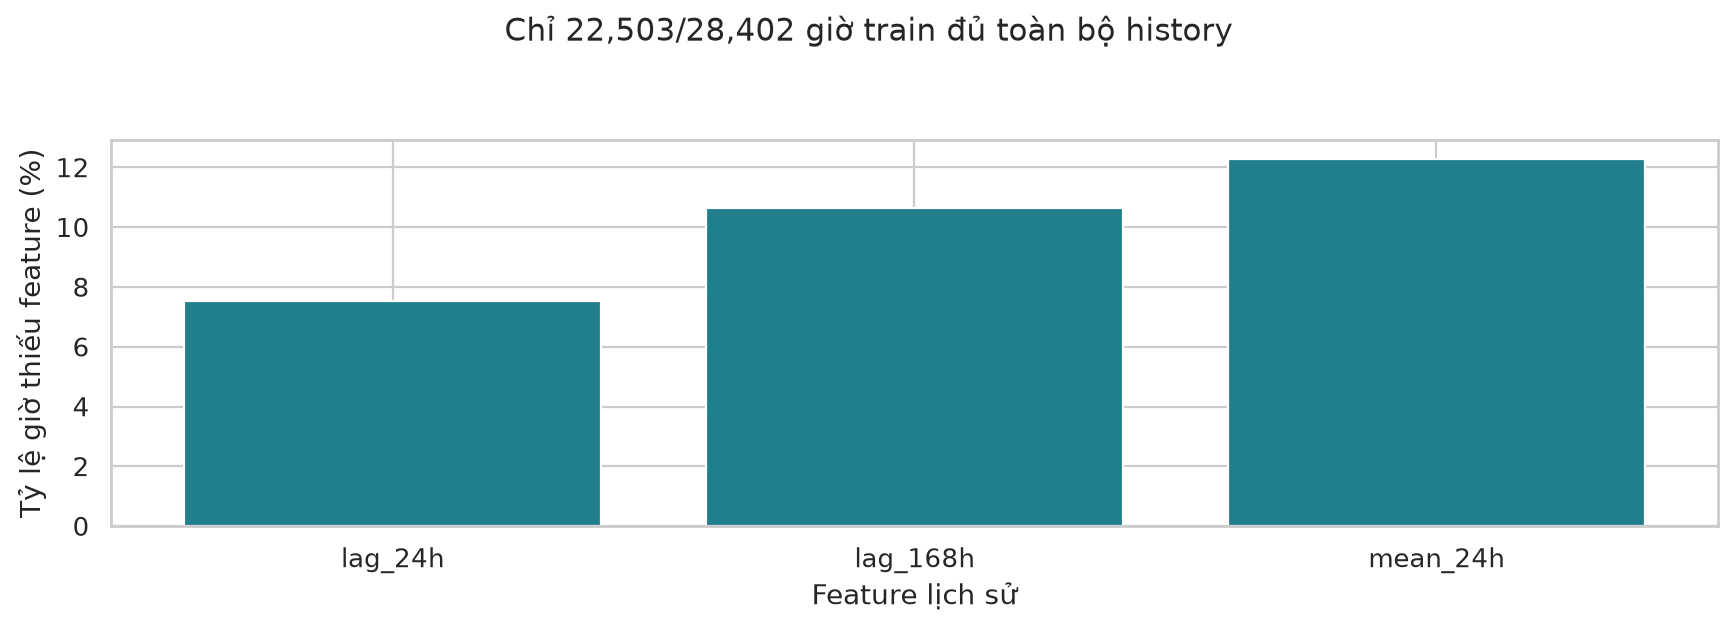

**Đọc biểu đồ này như sau:** Cột đo tỷ lệ thiếu từng feature, không cộng các cột vì các giờ thiếu có thể trùng nha Độ phủ phụ thuộc gaps và thời điểm đầu chuỗi.

In [34]:
fig,ax=plt.subplots(figsize=(11,4))
support=quality(train,HISTORY_FEATURES)
ax.bar(support.feature,support.missing_pct,color="#207E8D")
ax.set(xlabel="Feature lịch sử",ylabel="Tỷ lệ giờ thiếu feature (%)")
figure(context,"C",1,"history_missing",fig,
         f"Chỉ {len(history_cohort):,}/{len(train):,} giờ train đủ toàn bộ history",
         "Cột đo tỷ lệ thiếu từng feature, không cộng các cột vì các giờ thiếu có thể trùng nha Độ phủ phụ thuộc gaps và thời điểm đầu chuỗi.")

## 5. Quan hệ với mục tiêu

In [35]:
lag_relations=continuous_relation(train,HISTORY_FEATURES)
table(lag_relations)

,feature,Pearson,Spearman,n
0,lag_24h,0.862253,0.856568,26263
1,lag_168h,0.947225,0.943291,25383
2,mean_24h,0.187157,0.168577,24911


In [36]:
history_acf=acf_pairs(train,168)
table(history_acf)

,lag_hours,ACF,n
0,0,1.000000,28402
1,1,0.913758,25837
2,2,0.725023,26726
3,3,0.516859,26076
4,4,0.320027,26554
...,...,...,...
164,164,0.298920,25300
165,165,0.490913,25349
166,166,0.692516,25346
167,167,0.871103,25337


<Figure size 1320x440 with 1 Axes>

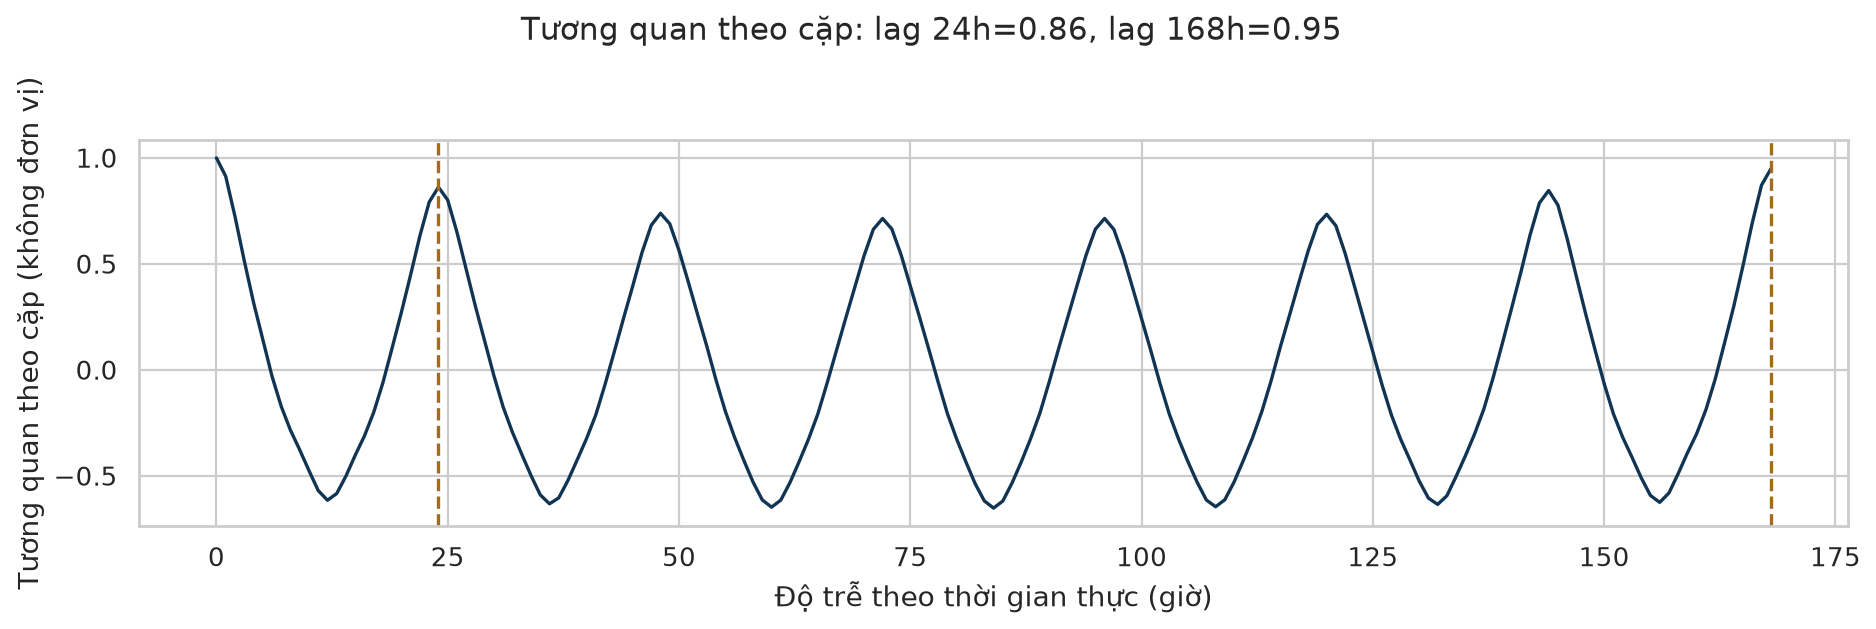

**Đọc biểu đồ này như sau:** ACF ở đây là Pearson theo các cặp giờ hợp lệ cho mỗi lag, không nối chuỗi qua gaps. n khác nhau theo lag; không gắn dải tin cậy white-noise mặc định.

In [37]:
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(history_acf.lag_hours,history_acf.ACF,color="#103451")
for lag in [24,168]: ax.axvline(lag,color="#A66A1F",linestyle="--")
ax.set(xlabel="Độ trễ theo thời gian thực (giờ)",ylabel="Tương quan theo cặp (không đơn vị)")
corr24=float(history_acf.loc[history_acf.lag_hours.eq(24),"ACF"].iloc[0])
corr168=float(history_acf.loc[history_acf.lag_hours.eq(168),"ACF"].iloc[0])
figure(context,"C",2,"acf",fig,f"Tương quan theo cặp: lag 24h={corr24:.2f}, lag 168h={corr168:.2f}",
         "ACF ở đây là Pearson theo các cặp giờ hợp lệ cho mỗi lag, không nối chuỗi qua gaps. n khác nhau theo lag; không gắn dải tin cậy white-noise mặc định.")

<Figure size 1540x440 with 6 Axes>

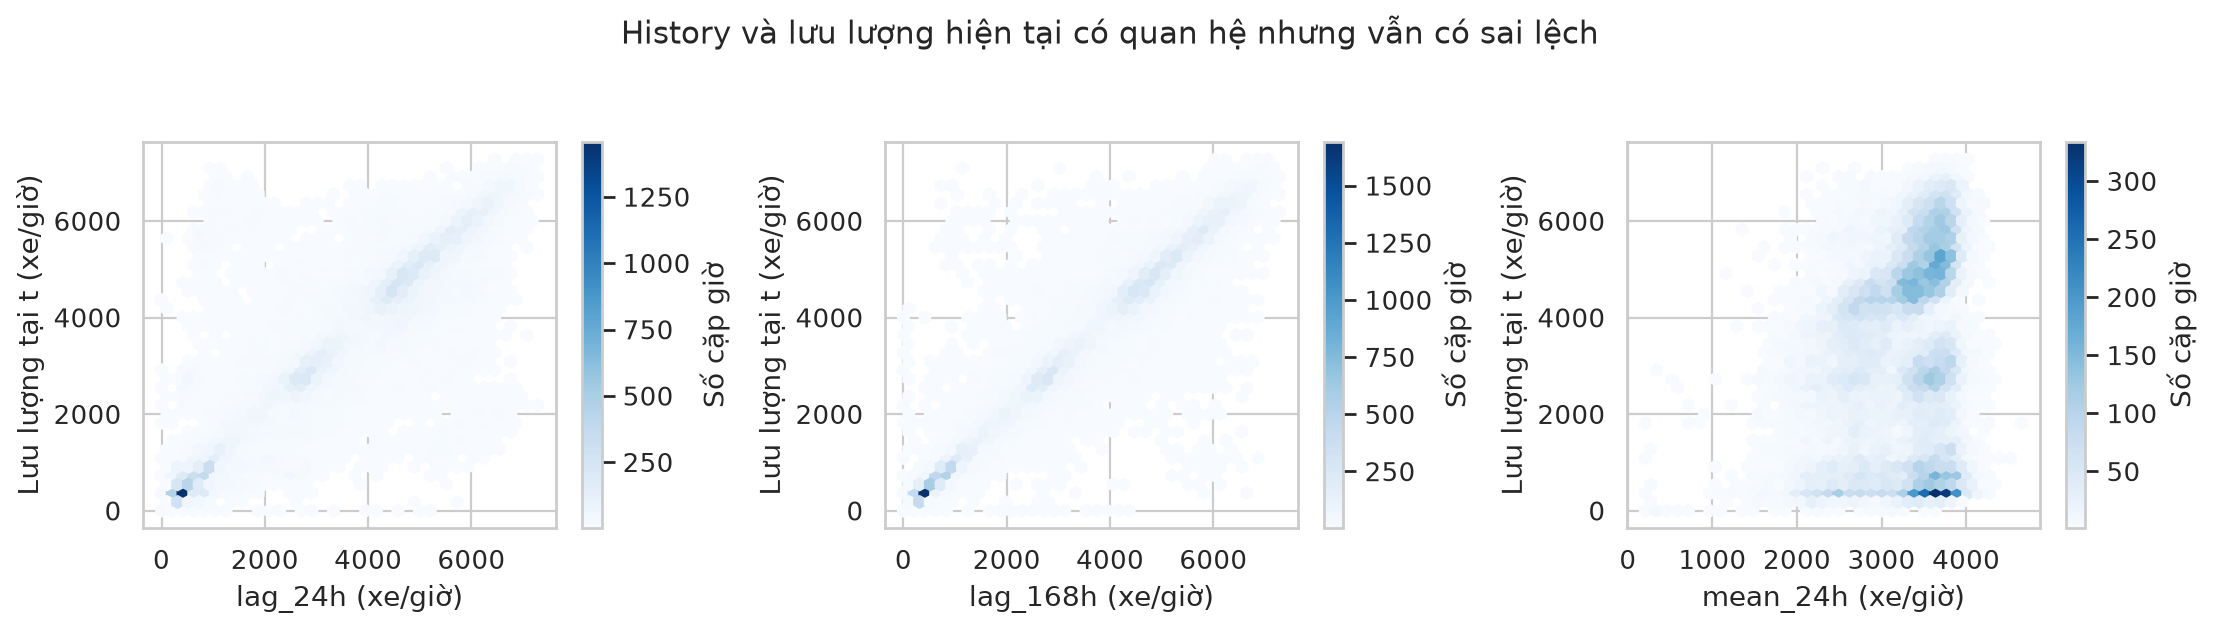

**Đọc biểu đồ này như sau:** Mỗi ô gom các cặp quá khứ/hiện tại. Đọc cùng Pearson, Spearman và n; tương quan cao chưa cho biết ích lợi ngoài B27.

In [38]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,f in zip(axes,HISTORY_FEATURES):
    pair=train[[f,"traffic_volume"]].dropna()
    image=ax.hexbin(pair[f],pair.traffic_volume,gridsize=35,mincnt=1,cmap="Blues")
    ax.set(xlabel=f"{f} (xe/giờ)",ylabel="Lưu lượng tại t (xe/giờ)")
    fig.colorbar(image,ax=ax,label="Số cặp giờ")
figure(context,"C",3,"lag_target",fig,"History và lưu lượng hiện tại có quan hệ nhưng vẫn có sai lệch",
         "Mỗi ô gom các cặp quá khứ/hiện tại. Đọc cùng Pearson, Spearman và n; tương quan cao chưa cho biết ích lợi ngoài B27.")

In [39]:
history_bins={f:binned(train,f) for f in HISTORY_FEATURES}
for frame in history_bins.values(): table(frame)

,bin,mean,n,feature,small_group
0,"(-0.01, 720.00]",597.576642,4384,lag_24h,False
1,"(720.00, 2185.00]",1778.824794,4372,lag_24h,False
2,"(2185.00, 3335.00]",2818.179534,4378,lag_24h,False
3,"(3335.00, 4551.00]",4132.592914,4375,lag_24h,False
4,"(4551.00, 5379.00]",4750.241891,4378,lag_24h,False
5,"(5379.00, 7280.00]",5431.427331,4376,lag_24h,False


,bin,mean,n,feature,small_group
0,"(-0.01, 716.00]",475.696176,4236,lag_168h,False
1,"(716.00, 2161.67]",1431.089941,4225,lag_168h,False
2,"(2161.67, 3318.00]",2860.840700,4231,lag_168h,False
3,"(3318.00, 4540.33]",4060.674704,4230,lag_168h,False
4,"(4540.33, 5365.00]",4844.211198,4233,lag_168h,False
5,"(5365.00, 7280.00]",5752.279801,4228,lag_168h,False


,bin,mean,n,feature,small_group
0,"(206.61, 2692.57]",2410.730010,4152,mean_24h,False
1,"(2692.57, 3119.26]",3136.421002,4152,mean_24h,False
2,"(3119.26, 3407.15]",3603.768545,4152,mean_24h,False
3,"(3407.15, 3593.94]",3492.082872,4151,mean_24h,False
4,"(3593.94, 3745.50]",3569.087187,4152,mean_24h,False
5,"(3745.50, 4654.00]",3346.898362,4152,mean_24h,False


In [40]:
corr_c,vif_c=correlation_and_vif(train,CONFIG_C)
table(vif_c)

,feature,VIF,note,n
0,hour,2.949974,chưa vượt ngưỡng mô tả 5,22493
1,day_of_week,8.740348,đa cộng tuyến tuyến tính,22493
2,month,2.655880,chưa vượt ngưỡng mô tả 5,22493
3,is_weekend,8.664356,đa cộng tuyến tuyến tính,22493
4,is_rush_hour,2.369807,chưa vượt ngưỡng mô tả 5,22493
5,hour_sin,2.849236,chưa vượt ngưỡng mô tả 5,22493
6,hour_cos,4.998159,chưa vượt ngưỡng mô tả 5,22493
7,day_of_week_sin,2.995963,chưa vượt ngưỡng mô tả 5,22493
8,day_of_week_cos,4.001881,chưa vượt ngưỡng mô tả 5,22493
9,month_sin,2.681964,chưa vượt ngưỡng mô tả 5,22493


<Figure size 1056x957 with 2 Axes>

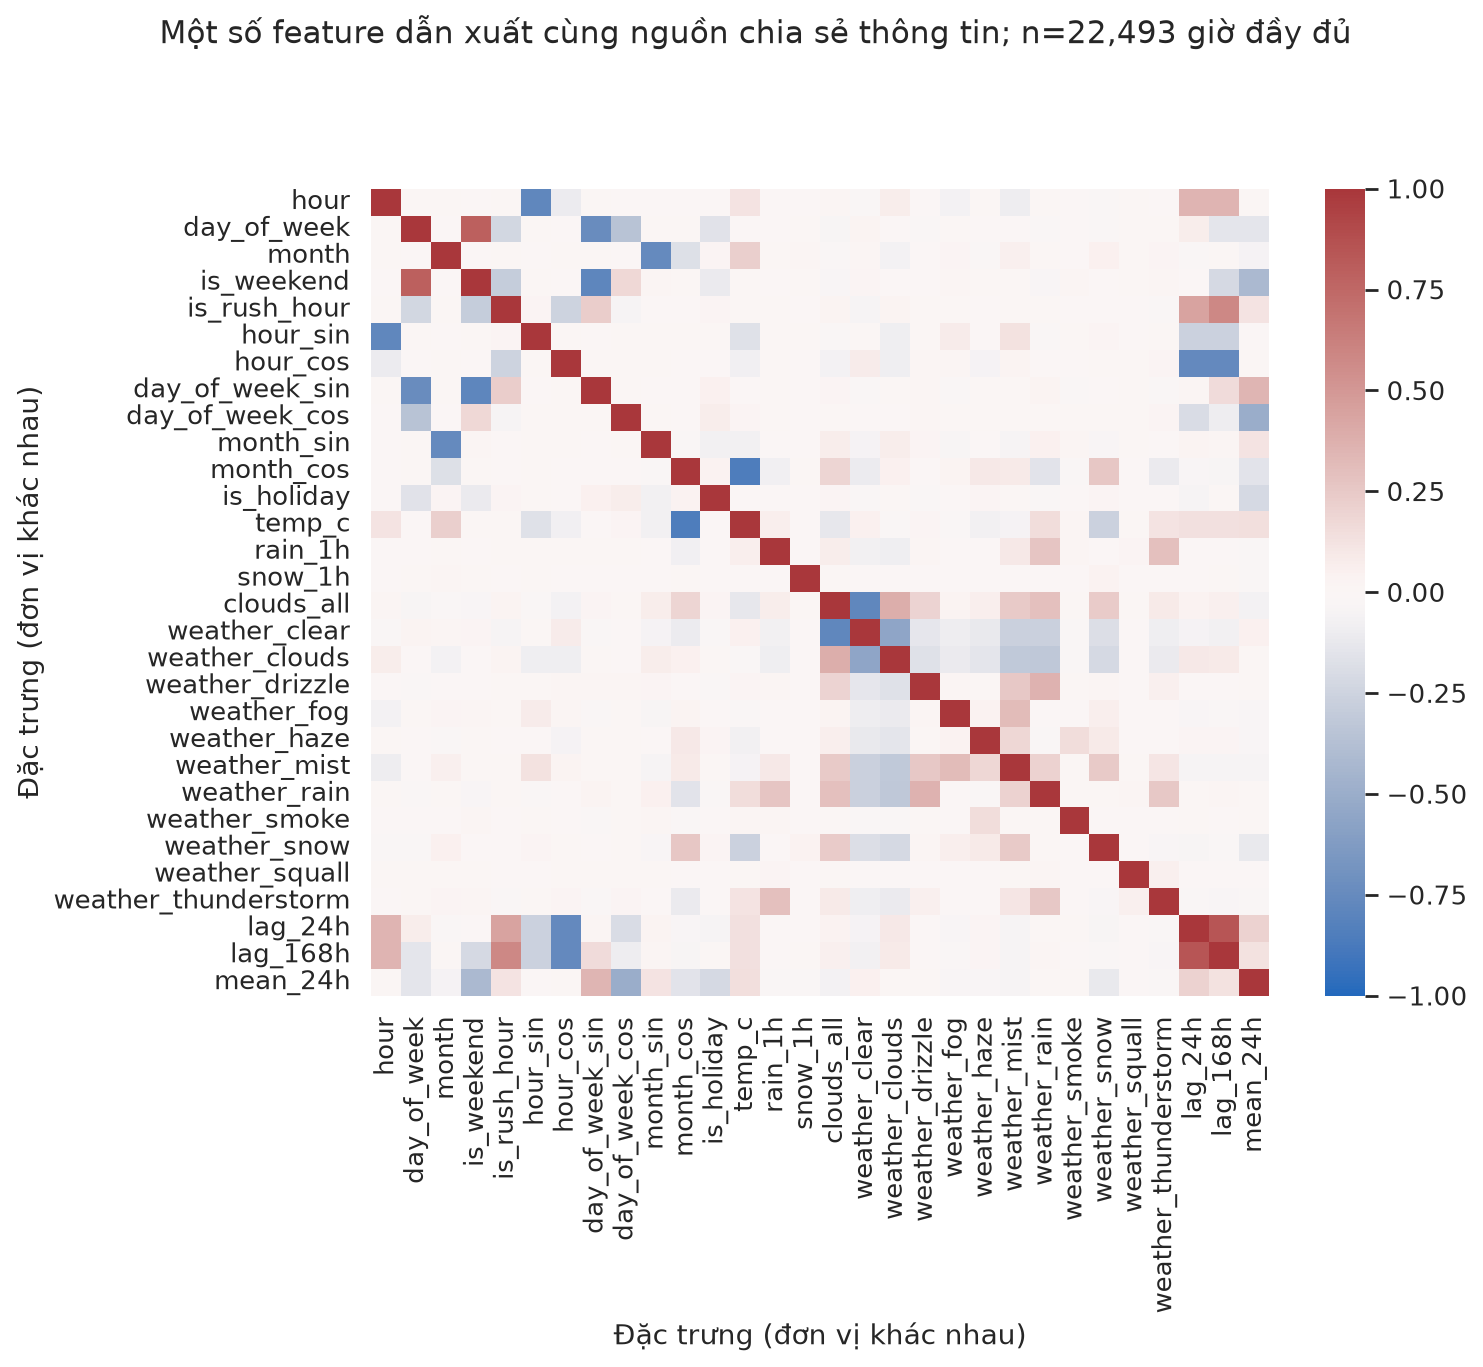

**Đọc biểu đồ này như sau:** Màu thể hiện Pearson giữa các feature, không dùng để đánh giá liên hệ của mã giờ/thứ/tháng thô với target. Ô trống là hệ số không xác định, thường do biến hằng; không tự bỏ feature chỉ từ hình này.

In [41]:
corr_plot(context,"C",corr_c,4,len(train[CONFIG_C].dropna()))

**Đối chứng B27/C30:** cả hai fit lại trên cùng cohort đủ ba feature history, cùng fold, RF và tham số như B. Held-out được đánh giá lần lượt theo giờ: history ở t có thể dùng y ở các giờ held-out trước t đã quan sát. Đây không phải dự báo cả cửa sổ held-out từ một thời điểm ban đầu. Imputer chỉ học phần fold-train; không điền các lag thiếu bằng giá trị target tương lai.

In [42]:
cv_bc=compare_cv(history_cohort,{"B27":CONFIG_B,"C30":CONFIG_C},"B27_vs_C30_same_history_cohort")
table(cv_bc)

,experiment,config,fold,fit_start,fit_end,score_start,score_end,n_fit,n,n_features,calendar_hours,MAE,RMSE,R2,score_timestamp_sha256
0,B27_vs_C30_same_history_cohort,B27,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,27,16931.0,266.752040,461.276879,0.945957,7988a87f60f4654090e59f97c1931ddc79507ab463d63d...
1,B27_vs_C30_same_history_cohort,C30,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,30,16931.0,245.787770,415.333421,0.956186,7988a87f60f4654090e59f97c1931ddc79507ab463d63d...
2,B27_vs_C30_same_history_cohort,B27,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,27,10163.0,323.600787,539.325938,0.923905,f8bf331df8204ef97049bc8b380a6d9b763a000509a835...
3,B27_vs_C30_same_history_cohort,C30,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,30,10163.0,262.069999,455.372117,0.945751,f8bf331df8204ef97049bc8b380a6d9b763a000509a835...
4,B27_vs_C30_same_history_cohort,B27,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,27,5867.0,283.339015,422.258506,0.953187,c9339d2a70b515cd2e0f105e820adbde03a49a452a7317...
5,B27_vs_C30_same_history_cohort,C30,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,30,5867.0,238.269332,369.116576,0.964228,c9339d2a70b515cd2e0f105e820adbde03a49a452a7317...


In [43]:
delta_bc=paired_delta(cv_bc,"B27","C30")
table(delta_bc)
say(f"[Quan sát] Chênh C-B trung bình fold: MAE {delta_bc.delta_MAE.mean():+.2f}, "
      f"RMSE {delta_bc.delta_RMSE.mean():+.2f} xe/giờ; C giảm MAE ở {int(delta_bc.delta_MAE.lt(0).sum())}/{len(delta_bc)} fold. "
      "Không so trực tiếp điểm B trong notebook B với B tại đây vì cohort/fold khác.")

,fold,delta_MAE,delta_RMSE,delta_R2,n
0,1,-20.964270,-45.943457,0.010229,5625
1,2,-61.530787,-83.953821,0.021847,5625
2,3,-45.069683,-53.141930,0.011042,5625


[Quan sát] Chênh C-B trung bình fold: MAE -42.52, RMSE -61.01 xe/giờ; C giảm MAE ở 3/3 fold. Không so trực tiếp điểm B trong notebook B với B tại đây vì cohort/fold khác.

<Figure size 1320x440 with 2 Axes>

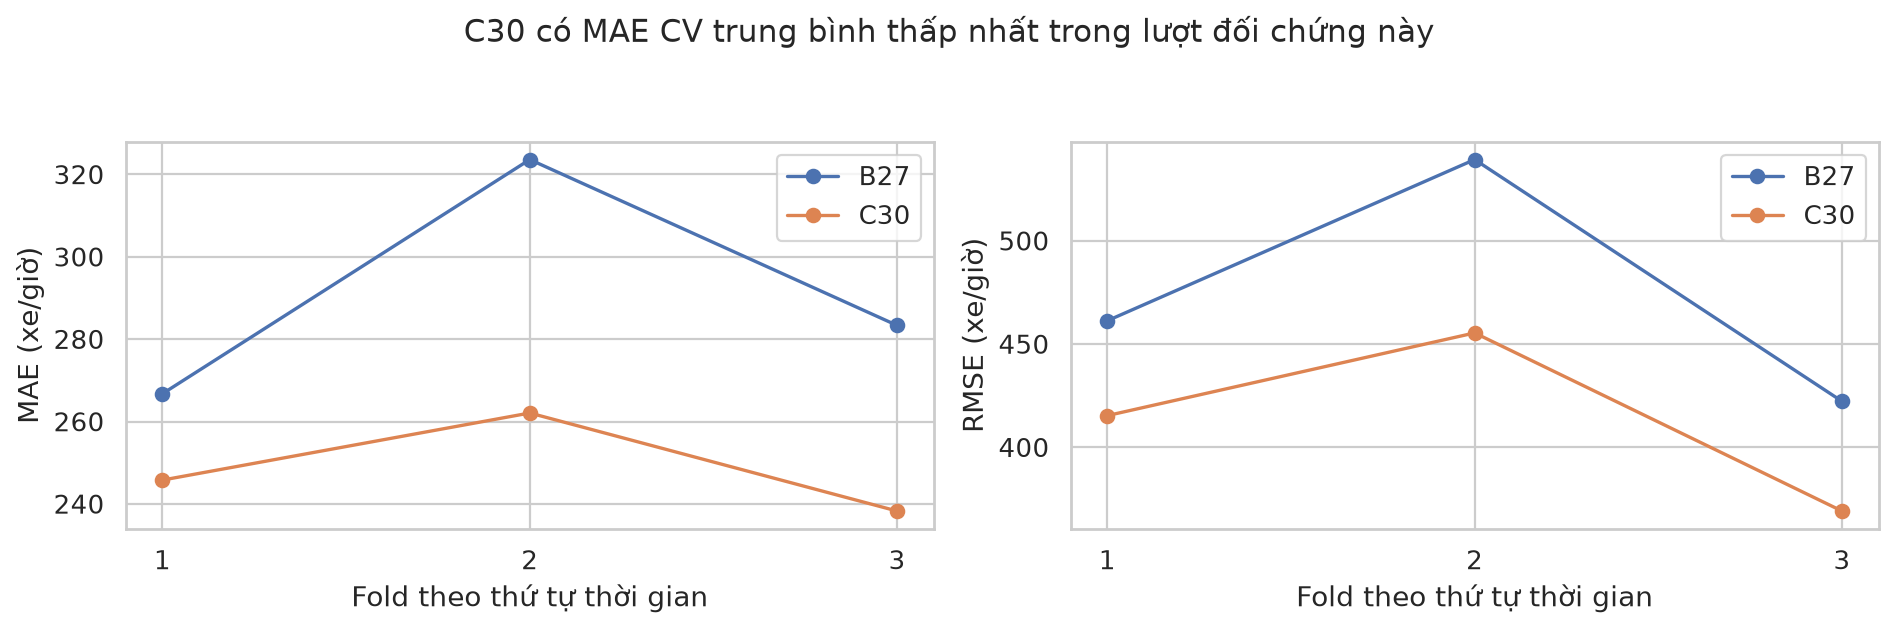

**Đọc biểu đồ này như sau:** So các đường tại cùng fold vì chúng chấm cùng timestamp. Mỗi fold có giai đoạn và lượng train khác nhau; không xem ba fold như ba thử nghiệm độc lập hoặc cửa sổ lịch bằng nhau.

In [44]:
cv_plot(context,"C",cv_bc,5)

## 6. Rủi ro rò rỉ và độ ổn định

In [45]:
# Kiểm tra lag tra đúng timestamp và việc dùng shift theo hàng sẽ khác.
for hours in [24,168]:
    expected=(train.date_time-pd.Timedelta(hours=hours)).map(history_series)
    pd.testing.assert_series_equal(train[f"lag_{hours}h"],expected,check_names=False)
lookup_checks=[]
for hours in [24,168]:
    wrong=train.traffic_volume.shift(hours)
    correct=train[f"lag_{hours}h"]
    differs=~(wrong.eq(correct) | (wrong.isna() & correct.isna()))
    lookup_checks.append(dict(lag_hours=hours,rows_differ_from_shift=int(differs.sum()),n=len(train)))
table(pd.DataFrame(lookup_checks))

,lag_hours,rows_differ_from_shift,n
0,24,11128,28402
1,168,20393,28402


In [46]:
# Can thiệp y(t) để kiểm tra chính giờ t không đi vào mean_24h(t).
check_time=train.loc[history_complete,"date_time"].iloc[len(history_cohort)//2]
changed=history_series.copy()
changed.loc[check_time]+=100000
original_mean=history_series.rolling("24h",closed="left",min_periods=MIN_HISTORY).mean().loc[check_time]
altered_mean=changed.rolling("24h",closed="left",min_periods=MIN_HISTORY).mean().loc[check_time]
assert np.isclose(original_mean,altered_mean)
# Thay y(t) và mọi giờ sau t cũng không được đổi feature tại t.
changed.loc[changed.index>=check_time]=999999
assert np.isclose(changed.rolling("24h",closed="left",min_periods=MIN_HISTORY).mean().loc[check_time],original_mean)
for hours in [24,168]:
    source_time=check_time-pd.Timedelta(hours=hours)
    assert source_time<check_time
    assert changed.get(source_time,np.nan)==history_series.get(source_time,np.nan)
say(f"[Quan sát] Kiểm tra can thiệp tại {check_time}: thay y(t) và tương lai không đổi history tại t. "
      "[Diễn giải] Kiểm tra này xác nhận logic timestamp/cửa sổ ở điểm thử, không thay cho giả định nguồn dữ liệu tới kịp lúc triển khai.")

[Quan sát] Kiểm tra can thiệp tại 2015-07-12 05:00:00: thay y(t) và tương lai không đổi history tại t. [Diễn giải] Kiểm tra này xác nhận logic timestamp/cửa sổ ở điểm thử, không thay cho giả định nguồn dữ liệu tới kịp lúc triển khai.

In [47]:
# Dữ liệu giả lập để kiểm tra biên cửa sổ, không phải kết quả giao thông.
probe = pd.DataFrame({"date_time": pd.date_range("2020-01-01", periods=200, freq="h"),
                      "traffic_volume": np.arange(200, dtype=float)})
probe_full = causal_history(probe)
probe_gapped = causal_history(probe.drop(index=10).reset_index(drop=True))
# Giờ t-24h bị thiếu: không lấy nhầm 24 hàng trước.
assert pd.isna(probe_gapped.loc[probe_gapped.date_time.eq(pd.Timestamp("2020-01-02 10:00")), "lag_24h"].iloc[0])
assert probe_gapped.loc[probe_gapped.date_time.eq(pd.Timestamp("2020-01-08 00:00")), "lag_168h"].iloc[0] == 0
# Cửa sổ chứa t-24h nhưng loại t; đủ 18 giờ mới tính mean.
assert probe_full.loc[24,"mean_24h"] == np.mean(np.arange(24))
assert pd.isna(probe_full.loc[17,"mean_24h"])
assert probe_full.loc[18,"n_history_24h"] == 18
assert pd.isna(probe_full.loc[18,"mean_24h_strict"])
say("[Quan sát] Các kiểm tra trên dữ liệu giả lập đều qua: lag không vượt khoảng thiếu, mean đúng biên và đúng số giờ tối thiểu. Đây là kiểm tra logic, không phải bằng chứng hiệu năng model.")

[Quan sát] Các kiểm tra trên dữ liệu giả lập đều qua: lag không vượt khoảng thiếu, mean đúng biên và đúng số giờ tối thiểu. Đây là kiểm tra logic, không phải bằng chứng hiệu năng model.

In [48]:
table(stability(train,HISTORY_FEATURES))

,year,feature,mean,missing_pct,n
0,2012,lag_24h,3239.638488,4.374703,2011
1,2012,lag_168h,3283.824907,10.651450,1879
2,2012,mean_24h,3223.494494,1.759391,2066
3,2013,lag_24h,3286.516695,10.076775,6559
4,2013,lag_168h,3276.231850,13.134083,6336
5,2013,mean_24h,3305.245641,13.819578,6286
6,2014,lag_24h,3251.854152,5.554321,4251
7,2014,lag_168h,3194.726355,9.797823,4060
8,2014,mean_24h,3256.439082,5.087758,4272
9,2015,lag_24h,3246.070305,13.303646,3115


[Diễn giải] Lag và rolling chỉ sẵn có nếu hệ thống đã ghi nhận lưu lượng quá khứ đúng hạn. Với dự báo nhiều bước từ một thời điểm, các giờ trung gian chưa quan sát không được lấy từ target thật. Cần protocol riêng nếu dùng dự báo đệ quy hoặc trực tiếp nhiều horizon.

Mean 18/24 dùng số quan sát thực thay đổi giữa các giờ, nên n_history_24h được giữ làm cột kiểm toán, chưa thêm vào C30. Đối chứng đủ 24 giờ ở đây mới kiểm tra độ phủ, chưa đo hiệu năng model theo quy tắc đó. DST chưa được xử lý; các lag là độ lệch trên timestamp đang có trong CSV.

## 7. Quyết định

In [49]:
decisions_c=plan_decisions("C",train)
table(decisions_c)

,feature,decision,evidence,n
0,hour,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
1,day_of_week,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
2,month,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
3,is_weekend,Giữ để đối chứng,"n1=8,108; cờ dẫn xuất từ lịch, có thể trùng th...",28402
4,is_rush_hour,Giữ để đối chứng,"n1=5,018; cờ dẫn xuất từ lịch, có thể trùng th...",28402
5,hour_sin,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
6,hour_cos,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
7,day_of_week_sin,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
8,day_of_week_cos,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402
9,month_sin,Giữ cấu hình tham chiếu,mẫu hình nhóm/VIF mô tả; chưa làm ablation riê...,28402


In [50]:
headline_c=f"Đủ history {len(history_cohort):,}/{len(train):,} giờ; C giảm MAE {int(delta_bc.delta_MAE.lt(0).sum())}/{len(delta_bc)} fold; delta MAE {delta_bc.delta_MAE.mean():+.2f}"
export_result(context,"C",headline_c,"Giữ C30 có điều kiện dữ liệu quá khứ; không chọn model cuối trước test",decisions_c,cv_bc,
                "Rolling cần ít nhất 18/24 giờ; cohort thay đổi; cần dữ liệu đến kịp; không đại diện dự báo nhiều bước")
say(f"[Quan sát] {headline_c}. [Diễn giải] Đây là kết quả của một model/seed và ba giai đoạn train, "
      "chưa cô lập đóng góp từng lag. Cần ablation từng history nếu muốn bỏ riêng một cột; giữ cấu hình tham chiếu trong khi chưa có bằng chứng đó.")

[Quan sát] Đủ history 22,503/28,402 giờ; C giảm MAE 3/3 fold; delta MAE -42.52. [Diễn giải] Đây là kết quả của một model/seed và ba giai đoạn train, chưa cô lập đóng góp từng lag. Cần ablation từng history nếu muốn bỏ riêng một cột; giữ cấu hình tham chiếu trong khi chưa có bằng chứng đó.

[Tài liệu API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html): TimeSeriesSplit mở rộng phần train; khi giờ bị thiếu, các fold cùng số hàng chưa chắc có cùng thời lượng lịch.
[pandas rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html) mô tả cửa sổ thời gian và `closed="left"`.
[Định nghĩa VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).